# Experiment 7e partial - ephemeral 4-think in Cooking, with CoT
A smaller version of `Experiment7e_EphemeralCoT.ipynb`, which would play 2000 games: here only er4-think (with the CoT prompt), only Cooking (levels 1-9) and only seeds 1-10, i.e. 90 games.
- er4 vs r4 is the main comparison; er10 can be added later.
- Cooking is where the configurations differ the most.
- 10 seeds are the same games of e1-think, and the first 10 seeds of r4/r10-think.

The results are saved in the same files of the full notebook, so the seeds already played (by either notebook) are skipped, and the full notebook can later continue from here.

# Setup
On Google Colab this clones the repository, installs TextWorld and moves into `Code/Experiments`. Locally (e.g. in the Docker container) it does nothing.
The first time on a new Colab machine the installation takes a few minutes: restart the kernel after it (and then run all the cells), because it can update torch.


In [1]:
import os
import sys
import shutil
import subprocess

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    repo_url = "https://github.com/UPROOT01/LLMs-Play-Textual-Games.git"
    repo_dir = "/content/LLMs-Play-Textual-Games"
    if not os.path.isfile(f"{repo_dir}/Code/Self-evaluation/self_evaluation.py"):
        shutil.rmtree(repo_dir, ignore_errors=True) # leftover of a failed clone
        # sparse clone: only the folders needed by the experiments are downloaded (the whole Games folder is >1 GB)
        subprocess.run(["git", "clone", "--depth", "1", "--filter=blob:none", "--sparse", repo_url, repo_dir], check=True)
    else:
        # already cloned in this runtime: only fetch the new commits (fails safely instead of overwriting local results)
        subprocess.run(["git", "-C", repo_dir, "pull", "--ff-only"], check=True)
    # the clone may come from another experiment's notebook: add the folders this one needs
    subprocess.run(["git", "-C", repo_dir, "sparse-checkout", "add",
                    "Code/Self-evaluation", "Code/Games/coin_collector", "Code/Games/cooking",
                    "Code/Games/treasure_hunter", "Code/Experiments/Experiment 7"], check=True)
    # vllm: generation engine used by parallel_play (n_parallel > 1); it may replace the installed torch version
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "textworld", "vllm==0.31.0"], check=True)
    os.chdir(f"{repo_dir}/Code/Experiments")

print("Working directory:", os.getcwd())

Working directory: /content/LLMs-Play-Textual-Games/Code/Experiments


On Colab the results are saved on Google Drive, because the files of the Colab machine are deleted together with it.
If mounting fails, use the VS Code command *Colab: Mount Google Drive to Server...*

In [2]:
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
import torch

assert torch.cuda.is_available(), "No GPU available: connect to a Colab runtime with a GPU (e.g. T4)"
! nvidia-smi

Wed Oct  7 16:44:01 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   57C    P8             17W /   72W |       3MiB /  23034MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [4]:
import pickle
sys.path.append("../Self-evaluation")

from self_evaluation import play, LLMAgentSelfEvaluate
from parallel_play import play_parallel

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

# Notebook variables

In [5]:
exp_number = 7
games_folder = "../Games"
seeds = range(1,11) # same seeds of e1-think, first 10 seeds of r4/r10-think
n_episodes = 1
max_steps = 100
n = 4 # only er4-think

levels = {"coin_collector": 14, "cooking": 9, "treasure_hunter": 27}
game = "cooking"
run_levels = range(1, 10)

# games played at the same time, with the answers generated in batches (see Self-evaluation/parallel_play.py)
# 1 = one game at a time, with the normal play()
n_parallel = 4

# episodes stuck in a loop (at most loop_max_distinct different turns among the last loop_window) are stopped early
loop_window = 20
loop_max_distinct = 2

# new results and logs: on Colab they go to Google Drive, so they survive the deletion of the Colab machine
if IN_COLAB:
    assert os.path.isdir("/content/drive/MyDrive"), "Google Drive is not mounted: run the cell above"
    results_folder = f"/content/drive/MyDrive/LLMs-Play-Textual-Games/Experiment {exp_number}"
else:
    results_folder = f"./Experiment {exp_number}"
print("Results folder:", results_folder)

with open(f"{games_folder}/max_scores_cooking.pickle", "rb") as f:
    max_scores_cooking = pickle.load(f)
os.makedirs(f"{results_folder}/logs/{game}", exist_ok=True)

Results folder: /content/drive/MyDrive/LLMs-Play-Textual-Games/Experiment 7


# Game running
The results are saved after every game: if the run is interrupted, running this cell again resumes from the first seed not yet played.
With `n_parallel > 1` the games end in any order, but each level's file only stores consecutive seeds: when interrupted, the games already finished after a missing seed are played again.

In [6]:
def results_path(level):
    return f"{results_folder}/er{n}think_{game}_level{level}.pickle"

def make_agent(level, seed, show_speed):
    return LLMAgentSelfEvaluate(selfeval_turns=n,
                                reads_own_reasoning=False, # ephemeral
                                random_selfeval=True,
                                prompt_version="CoT",
                                show_speed=show_speed,
                                log=f"{results_folder}/logs/{game}/er{n}think_level{level}-seed{seed}.log")

def game_path(level, seed):
    return f"{games_folder}/{game}/level{level}-seed{seed}.z8"

saved = {} # level -> results of the seeds played so far, in seed order
for level in run_levels:
    saved[level] = []
    if os.path.exists(results_path(level)):
        with open(results_path(level), "rb") as f:
            saved[level] = pickle.load(f)

def save(level):
    with open(results_path(level), "wb") as f:
        pickle.dump(saved[level], f)

if n_parallel == 1:
    for level in run_levels:
        for seed in seeds[len(saved[level]):]: # skip the seeds already played
            results = play(make_agent(level, seed, show_speed=True), game_path(level, seed),
                           max_steps=max_steps, n_episodes=n_episodes,
                           loop_window=loop_window, loop_max_distinct=loop_max_distinct)
            saved[level].append(results[0])
            save(level)
else:
    ended_early = {} # (level, seed) -> results of the games that ended before a lower seed of their level

    def on_result(key, result):
        ended_early[key] = result
        level = key[0]
        # store the consecutive seeds only, so that resuming from len(saved[level]) stays correct
        while len(saved[level]) < len(seeds) and (level, seeds[len(saved[level])]) in ended_early:
            saved[level].append(ended_early.pop((level, seeds[len(saved[level])])))
        save(level)

    jobs = [((level, seed), lambda level=level, seed=seed: make_agent(level, seed, show_speed=False), game_path(level, seed))
            for level in run_levels for seed in seeds[len(saved[level]):]] # skip the seeds already played
    print(f"{len(jobs)} games to play")
    play_parallel(jobs, n_parallel=n_parallel, max_steps=max_steps,
                  loop_window=loop_window, loop_max_distinct=loop_max_distinct, on_result=on_result)

80 games to play


Parse safetensors files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading safetensors checkpoint shards:   0% Completed | 0/3 [00:00<?, ?it/s]


[rank0]:W1007 16:45:15.200000 7373 torch/_inductor/utils.py:1953] Not enough SMs to use max_autotune_gemm mode
Capturing CUDA graphs (FULL): 100%|██████████| 2/2 [00:00<00:00, 13.53it/s]
2026-10-07 16:47:15,437 - INFO - core.py:564 - flashinfer.jit: Building JIT module sampling; this can take several minutes on first use.
Capturing CUDA graphs (FULL): 100%|██████████| 35/35 [00:02<00:00, 15.05it/s]


1 games running, 0 waiting; 79 ended (27.0 games/hour); 5042 tokens/min overall

../Games/cooking/level2-seed4.z8 steps: 28; score: 4 / 8; time: 155 s
../Games/cooking/level2-seed2.z8 steps: 28; score: 1 / 8; time: 198 s
../Games/cooking/level2-seed3.z8 steps: 35; score: 4 / 8; time: 200 s
../Games/cooking/level2-seed7.z8 steps: 27; score: 4 / 8; time: 75 s
../Games/cooking/level2-seed1.z8 steps: 100; score: 5 / 8; time: 521 s
../Games/cooking/level2-seed6.z8 steps: 59; score: 8 / 8; time: 325 s
../Games/cooking/level2-seed5.z8 steps: 69; score: 8 / 8; time: 633 s
../Games/cooking/level2-seed8.z8 loop detected, steps: 99; score: 0 / 8; time: 531 s
../Games/cooking/level2-seed10.z8 steps: 100; score: 5 / 8; time: 488 s
../Games/cooking/level2-seed9.z8 steps: 100; score: 4 / 8; time: 517 s
../Games/cooking/level3-seed1.z8 steps: 100; score: 8 / 11; time: 383 s
../Games/cooking/level3-seed2.z8 steps: 79; score: 5 / 11; time: 615 s
../Games/cooking/level3-seed3.z8 steps: 100; score: 5 / 11; time: 662 s
../Games/cooking/level3-seed4.z8 loop detected, steps: 91; score: 4

# Comparison
Average normalized final score per level, with the number of seeds in brackets (e1-think has only 10 seeds).
Execution times are not compared here: the episodes stopped because of a loop are shorter than in the other runs, and with `n_parallel > 1` the times are wall-clock times of games played together.

In [7]:
import numpy as np

models = ["0", "e1", "r4", "er4", "r10", "er10"]
print(game)
print("level" + "".join(f"{model + '-think':>14}" for model in models))
for level in run_levels:
    row = []
    for model in models:
        folder = results_folder if model.startswith("er") else f"./Experiment {exp_number}" # new results vs results of experiment 7
        path = f"{folder}/{model}think_{game}_level{level}.pickle"
        if not os.path.exists(path):
            row.append("-")
            continue
        with open(path, "rb") as f:
            results_all_seeds = pickle.load(f)[:len(seeds)]
        final_scores = np.array([run[-1][1] for run in results_all_seeds], dtype=float)
        if game == "cooking":
            final_scores /= max_scores_cooking[level - 1]
        row.append(f"{np.mean(final_scores):.2f} ({len(final_scores)})")
    print(f"{level:>5}" + "".join(f"{cell:>14}" for cell in row))

cooking
level       0-think      e1-think      r4-think     er4-think     r10-think    er10-think
    1     0.06 (10)     0.56 (10)     0.28 (10)     0.46 (10)     0.32 (10)      0.20 (1)
    2     0.09 (10)     0.62 (10)     0.39 (10)     0.54 (10)     0.34 (10)             -
    3     0.13 (10)     0.64 (10)     0.31 (10)     0.40 (10)     0.15 (10)             -
    4     0.10 (10)     0.52 (10)     0.20 (10)     0.62 (10)     0.34 (10)             -
    5     0.05 (10)     0.55 (10)     0.29 (10)     0.45 (10)     0.34 (10)             -
    6     0.07 (10)     0.40 (10)     0.23 (10)     0.45 (10)     0.21 (10)             -
    7     0.09 (10)     0.42 (10)     0.20 (10)     0.29 (10)     0.24 (10)             -
    8     0.08 (10)     0.38 (10)     0.24 (10)     0.25 (10)     0.15 (10)             -
    9     0.04 (10)     0.18 (10)     0.11 (10)     0.13 (10)     0.05 (10)             -


## Graph
Average normalized final score per level, with its 90% bootstrap confidence interval, on the same seeds of the table.
The graph is also saved as a PDF in the `graphs` folder next to the results.

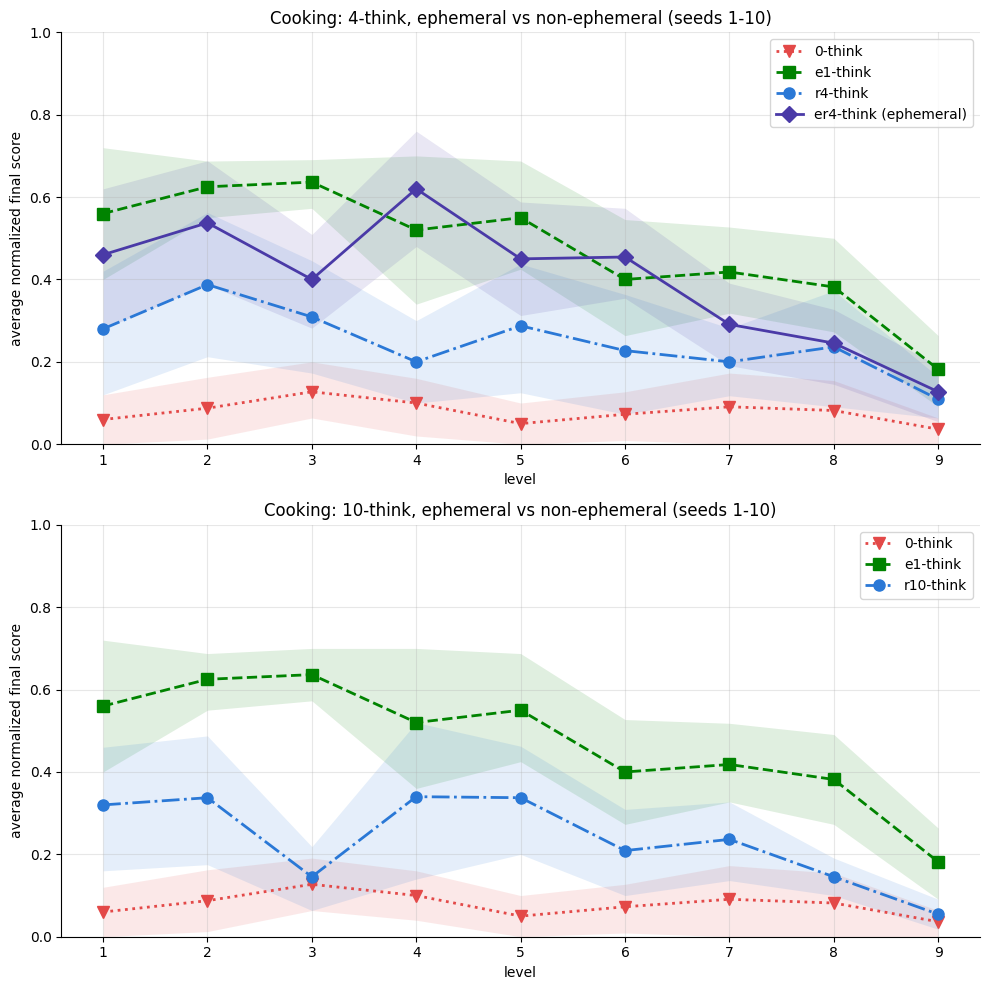

In [8]:
import matplotlib.pyplot as plt
from scipy.stats import bootstrap

def load_scores(model, level):
    """Normalized final scores of the first len(seeds) seeds, or None if the results do not exist."""
    folder = results_folder if model.startswith("er") else f"./Experiment {exp_number}"
    path = f"{folder}/{model}think_{game}_level{level}.pickle"
    if not os.path.exists(path):
        return None
    with open(path, "rb") as f:
        results_all_seeds = pickle.load(f)[:len(seeds)]
    final_scores = np.array([run[-1][1] for run in results_all_seeds], dtype=float)
    return final_scores / max_scores_cooking[level - 1]

# one panel per n: er{n}-think against r{n}-think, with 0- and e1-think as references (only if some er{n} results exist)
panels = [n_ for n_ in (4, 10) if any(load_scores(f"er{n_}", level) is not None for level in run_levels)]
# same color, line style and marker for the same role in every panel
styles = {"0":  dict(color="#e34948", linestyle=":",  marker="v"),
          "e1": dict(color="#008300", linestyle="--", marker="s"),
          "r":  dict(color="#2a78d6", linestyle="-.", marker="o"),
          "er": dict(color="#4a3aa7", linestyle="-",  marker="D")}

fig, axes = plt.subplots(len(panels), 1, figsize=(10, 5 * len(panels)), squeeze=False)
for ax, n_ in zip(axes[:, 0], panels):
    for model, role in [("0", "0"), ("e1", "e1"), (f"r{n_}", "r"), (f"er{n_}", "er")]:
        x, y, low, high = [], [], [], []
        for level in run_levels:
            scores = load_scores(model, level)
            if scores is None or len(scores) < 2:
                continue
            ci = bootstrap((scores,), np.mean, method="basic", n_resamples=1000, confidence_level=0.9).confidence_interval
            x.append(level)
            y.append(np.mean(scores))
            low.append(max(ci.low, 0) if np.isfinite(ci.low) else y[-1])
            high.append(min(ci.high, 1) if np.isfinite(ci.high) else y[-1])
        if not x:
            continue
        label = f"{model}-think" + (" (ephemeral)" if role == "er" else "")
        ax.fill_between(x, low, high, color=styles[role]["color"], alpha=0.12, linewidth=0)
        ax.plot(x, y, label=label, linewidth=2, markersize=8, **styles[role])
    ax.set_title(f"{game.capitalize()}: {n_}-think, ephemeral vs non-ephemeral (seeds {seeds[0]}-{seeds[-1]})")
    ax.set_xlabel("level")
    ax.set_ylabel("average normalized final score")
    ax.set_xticks(list(run_levels))
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend()
fig.tight_layout()

os.makedirs(f"{results_folder}/graphs", exist_ok=True)
fig.savefig(f"{results_folder}/graphs/er_vs_r_{game}.pdf", bbox_inches="tight")
plt.show()